## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 16.10.2026

Мягкий дедлайн: 16.11.2026 23:59 MSK

Жесткий дедлайн: 23.11.2026 23:59 MSK


### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: 10


**Выполнила:** Смахтина Яна, группа: 23.Б02


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже градиент для функции потерь MSE в матричном виде.**

**Решение:**

$$
    ∇_w Q(w) = \frac{2}{\ell}  X^T (Xw - y)
$$

- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**





### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
$$ w = (X^T X)^{-1} X^T y $$

**Вопрос**: Как мы помним, у аналитического решения есть минусы - какие?

**Ответ**:

 - **Вычислительная сложность по памяти и времени.** Вычисление произведения матриц $X^{T}X$ и обращение матрицы $(X^T X)^{-1}$ имеет сложность $O(n \cdot d^2 + d^3)$, где $d$ - количество признаков, а $n$ - количество объектов. Также матрицу $X^{T}X$ размера $d \times d$ нужно целиком хранить в оперативной памяти.
  - **Проблемы с мультиколлинеарностью (вырожденность матрицы).** Если признаки линейно зависят друг от друга (или сильно коррелируют), матрица $X^{T}X$ становится вырожденной (или близкой к сингулярной). В таком случае ее обращение математически невозможно (предельные ошибки округления или деление на ноль), что требует применения регуляризации или псевдообращения.
 - **Невозможность работы в режиме Online / Mini-batch.** Аналитическое решение требует всех данных сразу (batch-подход), чтобы составить и обработать матрицы $X$ и $y$. Его нельзя применять для потоковой обработки данных или обучения на огромных датасетах, которые не помещаются в оперативную память компьютера.
 - **Ограничения на функцию потерь.** Аналитическая формула выводится строго для среднеквадратичной ошибки (MSE).


Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [1]:
import numpy as np
from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

/content/interfaces.py:50: SyntaxWarning: invalid escape sequence '\h'
  returns: np.ndarray, вектор \hat{y}


In [2]:
from sklearn.metrics import mean_squared_error as mse
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.06965682452817414
Your MSE 0.06965682452817415


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [3]:
x[:, 3] = x[:, 2] + x[:, 4]

In [4]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

Sklearn MSE 0.07324876375222256
Your MSE 0.07324876375222257


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
$$ w = X^{+}y = \underset{k\times m}{\mathrm{V}} \ \underset{m\times m}{\mathrm{\Sigma}^{+}} \ \underset{m\times n}{\mathrm{U^T}}$$

где $\Sigma^{+}$ - псевдообратная матрица, которая получается из диагональной матрицы $\Sigma$ простым замещением всех ненулевых сингулярных чисел $\sigma _{i}$ на их обратные величины $1 / \sigma_i$.

**Ответ**: Это усеченное SVD (или решение через псевдообратную Мура–Пенроуза).
В нашем случае `x[:, 3] = x[:, 2] + x[:, 4]`, поэтому один столбец линейно зависим.

Ранг матрицы $X$ равен 4. С вероятностью 1 остальные столбцы линейно независимы,
поэтому достаточно 4 сингулярных чисел. `svds` с $k = min(n, d) - 1 = 4$ как раз
позволяет получить эти 4 ненулевых сингулярных числа, а нулевое можно отбросить.

In [5]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))


your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(),
                                      loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.07324876375222256
Your MSE 0.07324876375222257


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**


Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`.

**Примечание.** Команда `%load_ext autoreload` в текущем окружении (Colab, Python 3.13) падает с ошибкой
`ModuleNotFoundError: No module named 'imp'`: расширение `autoreload` в IPython все еще импортирует
модуль `imp`, удалённый из стандартной библиотеки начиная с Python 3.12.

Вместо autoreload использую ручной перезапуск после правок.

In [6]:
#%load_ext autoreload

In [7]:
#%autoreload 2

from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)

from linear_regression import CustomLinearRegression

In [8]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [9]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [10]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from descents import (
    ConstantLR, TimeDecayLR,
    VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import CustomLinearRegression

sns.set(style='darkgrid')

In [11]:
data = pd.read_csv('autos.csv')

In [12]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000.0,177.0,1500.0
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000.0,93.0,3600.0
2,bmw,3er,limousine,manuell,benzin,ja,102,150000.0,246.0,650.0
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000.0,140.0,2200.0
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000.0,136.0,2000.0


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное

In [13]:
categorical = []
numeric = []
other = []

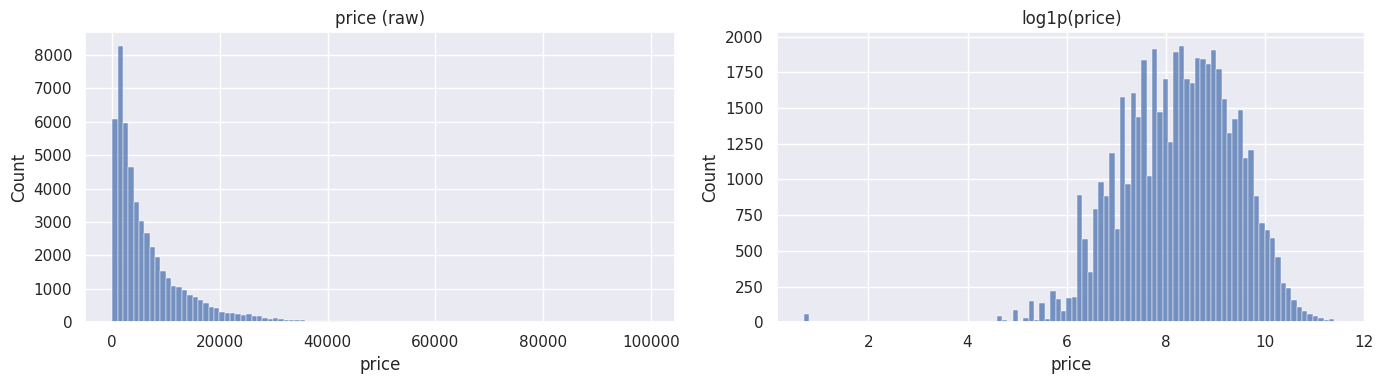

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data['price'], bins=100, ax=axes[0])
axes[0].set_title('price (raw)')
sns.histplot(np.log1p(data['price']), bins=100, ax=axes[1])
axes[1].set_title('log1p(price)')
plt.tight_layout(); plt.show()

In [15]:
print('before:', data.shape)
data = data[(data['price'] > 100) & (data['price'] < data['price'].quantile(0.999))]
data = data.reset_index(drop=True)
print('after:', data.shape)

before: (51385, 10)
after: (51198, 10)


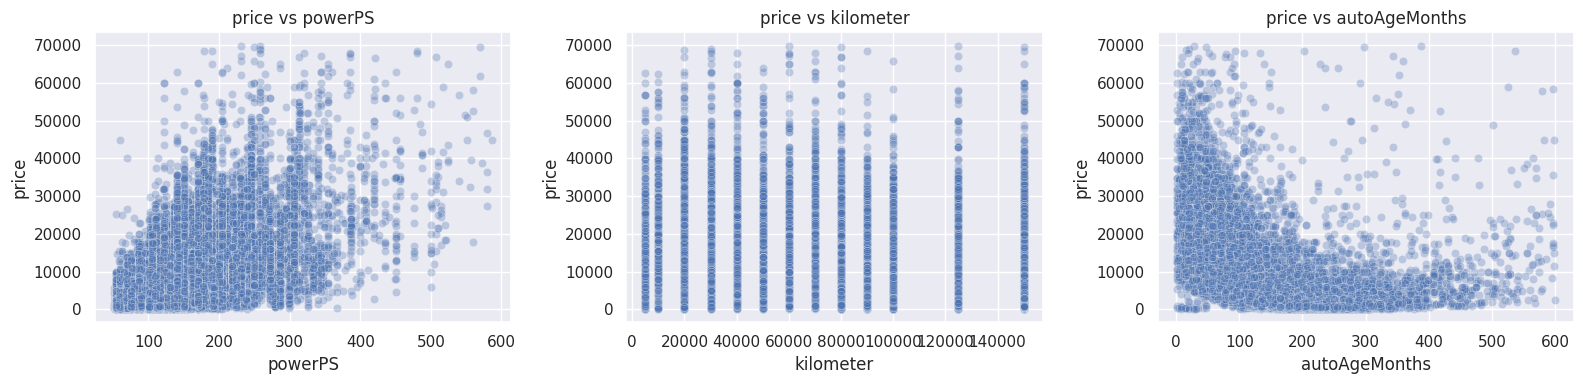

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['powerPS', 'kilometer', 'autoAgeMonths']):
    sns.scatterplot(data=data, x=col, y='price', alpha=0.3, ax=ax)
    ax.set_title(f'price vs {col}')
plt.tight_layout(); plt.show()

In [17]:
for col in ['brand', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']:
    print(f'\n--- {col} (уникальных: {data[col].nunique()}) ---')
    print(data[col].value_counts().head(10))


--- brand (уникальных: 38) ---
brand
volkswagen       10295
bmw               6232
mercedes_benz     5436
audi              5106
opel              5072
ford              3311
renault           2264
peugeot           1521
fiat              1185
skoda              982
Name: count, dtype: int64

--- vehicleType (уникальных: 8) ---
vehicleType
limousine     15394
kombi         10807
kleinwagen    10549
bus            5121
cabrio         3650
coupe          2846
suv            2500
andere          331
Name: count, dtype: int64

--- gearbox (уникальных: 2) ---
gearbox
manuell      38985
automatik    12213
Name: count, dtype: int64

--- fuelType (уникальных: 7) ---
fuelType
benzin     32503
diesel     17757
lpg          775
cng          101
hybrid        47
andere         8
elektro        7
Name: count, dtype: int64

--- notRepairedDamage (уникальных: 2) ---
notRepairedDamage
nein    46290
ja       4908
Name: count, dtype: int64


In [18]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric     = ['powerPS', 'kilometer', 'autoAgeMonths']
other       = []

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [19]:
data['bias'] = 1
other += ['bias']

x = data[categorical + numeric + other]
y = np.log1p(data['price'])

**Выводы по исследованию данных:**

- **Целевая переменная.** Распределение цены скошено вправо с длинным хвостом дорогих объявлений, поэтому мы переходим к $\log(1 + \text{price})$: на логарифмической шкале распределение ближе к симметричному, а MSE измеряет относительную ошибку цены.
- **Выбросы.** Удалены объявления с нереалистично низкой ценой ($\le 100$) и 0.1% самых дорогих (выше 99.9-го процентиля): 51385 -> 51198 объектов.
- **Полезные признаки.** По графикам цена заметно зависит от мощности, пробега и возраста автомобиля; категориальные признаки (бренд, модель, тип кузова, коробка, топливо, наличие неустраненных повреждений) тоже несут информацию о цене.
- **Преобразования.** Категориальные признаки кодируются One-Hot (после этого 306 столбцов), числовые стандартизуются, так как у них очень разный масштаб (пробег порядка $10^5$, мощность порядка $10^2$), а градиентные методы чувствительны к масштабу. Столбец `bias` не преобразуется.
- **Разбиение.** Данные делятся на train, val и test в отношении 8:1:1 (40958 / 5120 / 5120), а энкодер и скейлер обучаются только на train, чтобы не было утечки.

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print('train:', X_train.shape, 'val:', X_val.shape, 'test:', X_test.shape)

train: (40958, 10) val: (5120, 10) test: (5120, 10)


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

column_transformer = ColumnTransformer([
    ('ohe',     OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(),                       numeric),
    ('other',   'passthrough',                          other),
])

X_train = column_transformer.fit_transform(X_train).tocsr()
X_val   = column_transformer.transform(X_val).tocsr()
X_test  = column_transformer.transform(X_test).tocsr()

y_train = np.asarray(y_train, dtype=float).ravel()
y_val   = np.asarray(y_val,   dtype=float).ravel()
y_test  = np.asarray(y_test,  dtype=float).ravel()

print('X_train:', X_train.shape, X_train.dtype)
print('X_val:  ', X_val.shape)
print('X_test: ', X_test.shape)

X_train: (40958, 306) float64
X_val:   (5120, 306)
X_test:  (5120, 306)


## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [22]:
def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)

In [23]:
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display
import time
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.seterr(all="ignore")

lambda_grid = np.logspace(-3, 1, 9)

methods = {
    "Vanilla":  VanillaGradientDescent,
    "SGD":      StochasticGradientDescent,
    "SAG":      SAGDescent,
    "Momentum": MomentumDescent,
    "Adam":     Adam,
}

results = {}

for name, optimizer_cls in methods.items():
    best = None
    for lam in lambda_grid:
        set_seed(42)
        optimizer = optimizer_cls(lr_schedule=TimeDecayLR(lambda_=float(lam)))
        model = CustomLinearRegression(optimizer, loss_function=MSELoss())

        t0 = time.time()
        model.fit(X_train, y_train)
        elapsed = time.time() - t0

        if isinstance(optimizer, SAGDescent):
            optimizer.grad_memory = None

        if not np.all(np.isfinite(model.w)):
            continue

        val_pred = model.predict(X_val)
        val_mse = mean_squared_error(y_val, val_pred)
        if not np.isfinite(val_mse):
            continue

        if best is None or val_mse < best["val_mse"]:
            train_pred = model.predict(X_train)
            test_pred = model.predict(X_test)
            iters = len(model.loss_history) - 1
            best = {
                "lambda_": float(lam),
                "train_mse": mean_squared_error(y_train, train_pred),
                "val_mse": val_mse,
                "test_mse": mean_squared_error(y_test, test_pred),
                "r2_train": r2_score(y_train, train_pred),
                "r2_val": r2_score(y_val, val_pred),
                "r2_test": r2_score(y_test, test_pred),
                "iterations": iters,
                "converged": iters < optimizer.max_iter,
                "time": elapsed,
                "model": model,
            }

    if best is None:
        print(f"{name}: все значения lambda разошлись")
        continue
    results[name] = best

results_table = pd.DataFrame(
    [{"method": n, "lambda": r["lambda_"],
      "train_MSE": r["train_mse"], "val_MSE": r["val_mse"], "test_MSE": r["test_mse"],
      "train_R2": r["r2_train"], "val_R2": r["r2_val"], "test_R2": r["r2_test"],
      "iterations": r["iterations"], "converged": r["converged"], "time_s": r["time"]}
     for n, r in results.items()]
).sort_values("val_MSE")

display(results_table.round(5))

,method,lambda,train_MSE,val_MSE,test_MSE,train_R2,val_R2,test_R2,iterations,converged,time_s
3,Momentum,1.00000,0.26318,0.26360,0.25300,0.78466,0.78790,0.79895,820,True,2.52185
4,Adam,1.00000,0.25752,0.26409,0.24976,0.78929,0.78751,0.80152,1000,False,2.76937
0,Vanilla,1.00000,0.28727,0.28008,0.28076,0.76495,0.77465,0.77688,389,True,1.07502
1,SGD,0.31623,0.30498,0.29499,0.30313,0.75046,0.76265,0.75911,1000,False,1.09680
2,SAG,1.00000,1.47021,1.45981,1.53599,-0.20296,-0.17457,-0.22062,1000,False,8.30422


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

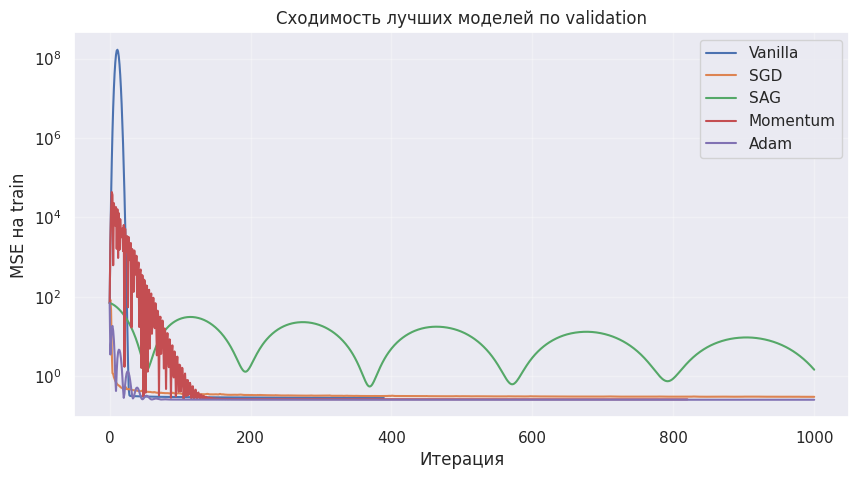

In [24]:
plt.figure(figsize=(10, 5))

for name, res in results.items():
    hist = res["model"].loss_history
    plt.plot(np.arange(len(hist)), hist, label=name)

plt.yscale("log")
plt.xlabel("Итерация")
plt.ylabel("MSE на train")
plt.title("Сходимость лучших моделей по validation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Выводы по таблице и графику:**

- **Качество.** Лучшие методы - **Momentum** и **Adam**: у Momentum val MSE = 0.2636, $R^2_{val} = 0.7879$, $R^2_{test} = 0.7990$; у Adam val MSE = 0.2641, $R^2_{val} = 0.7875$, $R^2_{test} = 0.8015$. Разница по валидации ($5 \cdot 10^{-4}$) пренебрежимо мала, на тесте Adam чуть лучше, поэтому эти два метода можно считать эквивалентными по качеству. Далее идут **Vanilla** $(R^2_{val} = 0.7747$, $R^2_{test} = 0.7769$) и **SGD** ($0.7627 / 0.7591$). **SAG** заметно хуже всех: $R^2_{val} = -0.1746$, то есть модель хуже константного предсказания.
- **Переобучения нет.** У всех методов, кроме SAG, $R^2$ на train, val и test близки (например, у Momentum $0.7847 / 0.7879 / 0.7990$). Лучшие методы выходят на $R^2 \approx 0.8$ на всех выборках, и разница между Momentum/Adam и Vanilla около 0.02 по $R^2$, то есть мала по сравнению с провалом SAG. Для этой линейной модели метод оптимизации важен в первую очередь для скорости и надежности сходимости.
- **Сходимость.** По критерию $\|\Delta w\|^2 < 10^{-6}$ остановились Vanilla (389 итераций) и Momentum (820). Adam, SGD и SAG дошли до `max_iter = 1000`. Важно: Vanilla остановилась раньше всех, но с худшим качеством, чем у Momentum и Adam. Критерий смотрит на норму шага $\eta_t \nabla Q$, а $\eta_t = \lambda / \sqrt{1 + t}$ убывает со временем, поэтому шаг становится малым и тогда, когда оптимум ещё не достигнут. Быстрая остановка здесь не означает лучшее решение. Momentum при том же $\lambda = 1$ накапливает скорость, поэтому эффективный шаг у него больше, и он доходит до лучшего решения.
- **SGD** (batch = 32) использует шумную оценку градиента по 32 объектам. Шум не затухает, поэтому норма шага не опускается ниже порога, и критерий не срабатывает, а качество ниже, чем у методов с полным градиентом.
- **SAG** плохо работает при `max_iter = 1000` и `batch_size = 32`. Таблица градиентов инициализируется нулями, а сумма делится на $n$, поэтому в начале оценка градиента занижена. К тысячной итерации просмотрено лишь около половины объектов, а сохраненные градиенты остальных соответствуют устаревшим весам. Оптимум $\lambda = 1$ лежит внутри сетки, а не на границе, то есть дело не в неудачной сетке, а в самом методе при таком бюджете итераций.
- **Время.** Стоимость одной итерации у Vanilla, Momentum и Adam около 3 мс, у SGD около 1.1 мс, у SAG около 8.3 мс. SGD всего примерно в 2.5 раза дешевле полного градиента, потому что на каждой итерации считается лосс по всей обучающей выборке для истории (`loss_history`). SAG дороже всех, потому что градиенты считаются по одному объекту в цикле Python, плюс обновляется таблица.

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

In [25]:
batch_sizes = [1, 8, 16, 32, 64, 128, 256, 512]
n_repeats = 5
lambda_grid_sgd = np.logspace(-3, 2, 11)
max_iter_sgd = 3000

def fit_sgd(bs, lam, seed, max_iter=max_iter_sgd):
    set_seed(seed)
    optimizer = StochasticGradientDescent(
        lr_schedule=TimeDecayLR(lambda_=float(lam)),
        batch_size=bs,
        tolerance=1e-6,
        max_iter=max_iter,
    )
    model = CustomLinearRegression(optimizer=optimizer, loss_function=MSELoss())
    t0 = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - t0
    iters = len(model.loss_history) - 1
    converged = iters < max_iter
    val_mse = mean_squared_error(y_val, model.predict(X_val))
    return elapsed, iters, converged, val_mse

batch_rows = []

for bs in batch_sizes:
    best = None
    for lam in lambda_grid_sgd:
        try:
            _, _, _, val_mse = fit_sgd(bs, lam, seed=42)
        except Exception:
            continue
        if not np.isfinite(val_mse):
            continue
        if best is None or val_mse < best[0]:
            best = (val_mse, float(lam))
    if best is None:
        print(f"bs={bs}: не удалось подобрать lr")
        continue

    best_lr = best[1]

    times, iters_list, convs = [], [], []
    for k in range(n_repeats):
        elapsed, it, conv, _ = fit_sgd(bs, best_lr, seed=1000 + k)
        times.append(elapsed)
        iters_list.append(it)
        convs.append(conv)

    batch_rows.append({
        "batch_size": bs,
        "best_lambda": best_lr,
        "mean_time": float(np.mean(times)),
        "mean_iterations": float(np.mean(iters_list)),
        "share_converged": float(np.mean(convs)),
    })

batch_results = pd.DataFrame(batch_rows)
display(batch_results.round(3))

,batch_size,best_lambda,mean_time,mean_iterations,share_converged
0,1,0.100,0.125,105.8,1.0
1,8,0.316,3.429,3000.0,0.0
2,16,0.316,3.274,3000.0,0.0
3,32,0.316,3.211,3000.0,0.0
4,64,0.316,3.271,2953.2,0.2
5,128,0.316,2.779,2384.0,1.0
6,256,0.316,1.673,1372.0,1.0
7,512,0.316,0.874,817.8,1.0


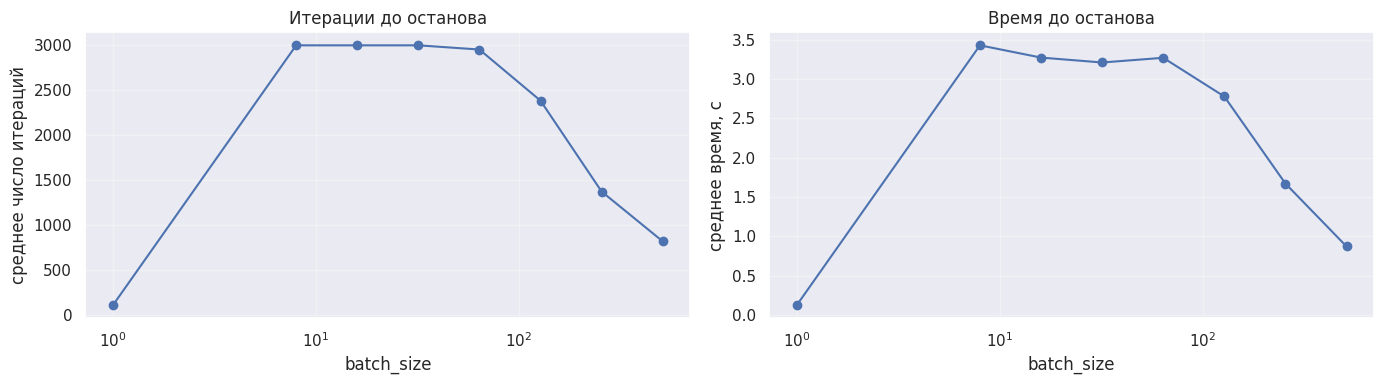

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(batch_results["batch_size"], batch_results["mean_iterations"], marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("batch_size")
axes[0].set_ylabel("среднее число итераций")
axes[0].set_title("Итерации до останова")
axes[0].grid(True, alpha=0.3)

axes[1].plot(batch_results["batch_size"], batch_results["mean_time"], marker="o")
axes[1].set_xscale("log")
axes[1].set_xlabel("batch_size")
axes[1].set_ylabel("среднее время, с")
axes[1].set_title("Время до останова")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Анализ таблицы:**

- **Не все запуски сошлись.** При `batch_size` = 8, 16, 32 все 5 запусков дошли до `max_iter = 3000`, при 64 сошлась лишь пятая часть (`share_converged = 0.2`). Для этих строк среднее число итераций - это среднее до лимита, а не до сходимости, поэтому сравнивать их между собой не нужно.
- **При `batch_size` >= 128 сходятся все запуски, и число шагов монотонно падает:** 2384 -> 1372 -> 818 (для 128, 256, 512). Время падает так же: 2.78 -> 1.67 -> 0.87 с. Чем больше батч, тем меньше шум оценки градиента, тем раньше норма шага $\|\Delta w\|^2$ опускается ниже порога.
- **Время пропорционально числу итераций.** Время одной итерации почти не зависит от размера батча (около 1.1 мс и для 32, и для 512). Это связано с тем, что на каждой итерации считается лосс по всей обучающей выборке (`loss_history`), и он перекрывает разницу в стоимости самого шага. В реальном применении без отслеживания полного лосса большие батчи были бы заметно дороже на итерацию, и выигрыш по времени был бы меньше.
- **`batch_size = 1` - артефакт критерия остановки.** Запуск останавливается в среднем за 106 итераций, и все запуски «сошлись». Но при одном объекте шаг $\eta_t \nabla Q_i$ может оказаться маленьким просто потому, что у этого объекта малая невязка, и критерий $\|\Delta w\|^2 < 10^{-6}$ срабатывает преждевременно. Малое время при `batch_size = 1` поэтому не означает, что метод быстро нашёл решение, и сравнивать его с остальными нельзя.
- **Вывод про выбор размера батча.** На этой задаче с фиксированным критерием остановки лучше брать большой батч (256-512): сходимость надёжнее и быстрее. Маленький батч даёт шум, из-за которого за ограниченное число итераций критерий не срабатывает. Нужно помнить, что $\lambda$ подбиралась отдельно для каждого размера по одному запуску (`seed=42`), а в таблице нет качества модели, поэтому сравнение по скорости сходимости не заменяет сравнения по качеству.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

In [32]:
from linear_regression import L2Regularization

mu_grid = [1e-4, 1e-3, 1e-2, 1e-1]

results_l2 = {}

for name, optimizer_cls in methods.items():
    best = None
    for mu in mu_grid:
        for lam in lambda_grid:
            set_seed(42)
            optimizer = optimizer_cls(lr_schedule=TimeDecayLR(lambda_=float(lam)))
            model = CustomLinearRegression(
                optimizer, loss_function=L2Regularization(MSELoss(), mu_rate=mu)
            )
            model.fit(X_train, y_train)

            if isinstance(optimizer, SAGDescent):
                optimizer.grad_memory = None

            if not np.all(np.isfinite(model.w)):
                continue

            val_pred = model.predict(X_val)
            val_mse = mean_squared_error(y_val, val_pred)
            if not np.isfinite(val_mse):
                continue

            if best is None or val_mse < best["val_mse"]:
                train_pred = model.predict(X_train)
                test_pred = model.predict(X_test)
                iters = len(model.loss_history) - 1
                best = {
                    "lambda_": float(lam),
                    "mu": mu,
                    "train_mse": mean_squared_error(y_train, train_pred),
                    "val_mse": val_mse,
                    "test_mse": mean_squared_error(y_test, test_pred),
                    "r2_train": r2_score(y_train, train_pred),
                    "r2_val": r2_score(y_val, val_pred),
                    "r2_test": r2_score(y_test, test_pred),
                    "iterations": iters,
                    "converged": iters < optimizer.max_iter,
                    "w": model.w.copy(),
                }

    if best is not None:
        results_l2[name] = best

rows = []
for name, r in results_l2.items():
    base = results[name]
    rows.append({
        "method": name,
        "lambda (no L2)": base["lambda_"], "lambda (L2)": r["lambda_"], "mu": r["mu"],
        "train_MSE (no L2)": base["train_mse"], "train_MSE (L2)": r["train_mse"],
        "test_MSE (no L2)": base["test_mse"], "test_MSE (L2)": r["test_mse"],
        "train_R2 (no L2)": base["r2_train"], "train_R2 (L2)": r["r2_train"],
        "test_R2 (no L2)": base["r2_test"], "test_R2 (L2)": r["r2_test"],
        "iters (no L2)": base["iterations"], "iters (L2)": r["iterations"],
        "converged (no L2)": base["converged"], "converged (L2)": r["converged"],
    })

l2_table = pd.DataFrame(rows).set_index("method")
display(l2_table.round(5).T)

method,Vanilla,SGD,SAG,Momentum,Adam
lambda (no L2),1.0,0.31623,1.0,1.0,1.0
lambda (L2),1.0,0.31623,1.0,1.0,1.0
mu,0.0001,0.001,0.1,0.0001,0.001
train_MSE (no L2),0.28727,0.30498,1.47021,0.26318,0.25752
train_MSE (L2),0.28733,0.30497,0.71729,0.2635,0.26337
test_MSE (no L2),0.28076,0.30313,1.53599,0.253,0.24976
test_MSE (L2),0.28083,0.3031,0.74649,0.25332,0.25443
train_R2 (no L2),0.76495,0.75046,-0.20296,0.78466,0.78929
train_R2 (L2),0.7649,0.75047,0.4131,0.7844,0.7845
test_R2 (no L2),0.77688,0.75911,-0.22062,0.79895,0.80152


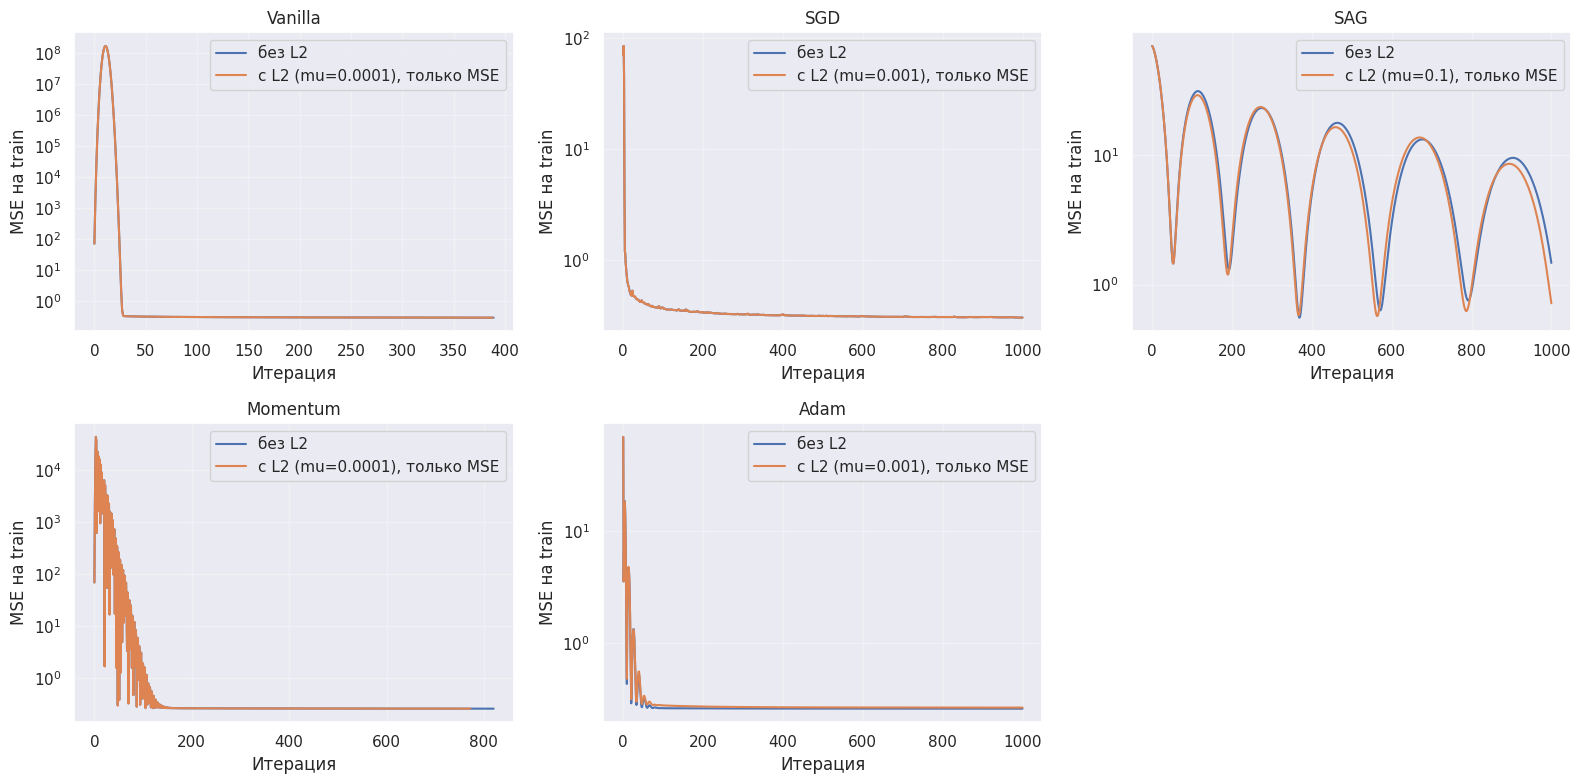

In [33]:
class MSETrackingL2(L2Regularization):
    def __init__(self, core_loss, mu_rate):
        super().__init__(core_loss, mu_rate)
        self.mse_history = []

    def loss(self, X, y, w):
        mse_value = self.core_loss.loss(X, y, w)
        self.mse_history.append(mse_value)
        return mse_value + 0.5 * self.mu_rate * float(np.sum(w ** 2))


fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, (name, r) in zip(axes.flat, results_l2.items()):
    set_seed(42)
    tracking_loss = MSETrackingL2(MSELoss(), r["mu"])
    optimizer = methods[name](lr_schedule=TimeDecayLR(lambda_=r["lambda_"]))
    model = CustomLinearRegression(optimizer, loss_function=tracking_loss)
    model.fit(X_train, y_train)
    if isinstance(optimizer, SAGDescent):
        optimizer.grad_memory = None
    assert np.allclose(model.w, r["w"])

    ax.plot(results[name]["model"].loss_history, label="без L2")
    ax.plot(tracking_loss.mse_history, label=f"с L2 (mu={r['mu']:g}), только MSE")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Итерация")
    ax.set_ylabel("MSE на train")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Выводы по регуляризации:**

- **Лучший $\mu$ почти везде минимальный или близкий к нему** ($10^{-4}$ у Vanilla и Momentum, $10^{-3}$ у SGD и Adam), а $\lambda$ при добавлении $L_2$ не изменилась ни у одного метода. То есть сильная регуляризация на валидации не помогает.
- **Качество на train и test практически не меняется.** У Vanilla, SGD и Momentum MSE на test меняется в третьем-четвертом знаке (например, у Vanilla 0.28076 -> 0.28083, у Momentum 0.25300 -> 0.25332), $R^2_{test}$ меняется не более чем на $3 \cdot 10^{-4}$. У Adam качество слегка ухудшилось: test MSE 0.24976 -> 0.25443, $R^2_{test}$ 0.8015 -> 0.7978. Ошибка на train у Vanilla, Momentum и Adam с $L_2$ немного выросла (например, у Adam 0.25752 -> 0.26337), у SGD практически не изменилась (0.30498 -> 0.30497); это ожидаемо, так как штраф ограничивает множество решений, и минимум MSE на train в точке оптимума не может стать меньше. Случай SAG разобран ниже.
- **Объяснение.** Регуляризация борется с переобучением, а его здесь нет: у модели 306 признаков и около 41 тысячи объектов, $R^2$ на train, val и test почти совпадают (у Momentum $0.785 / 0.788 / 0.799$). Нечего исправлять, поэтому штраф лишь слегка смещает решение от оптимума по MSE.
- **Сходимость.** Число итераций у Vanilla практически не изменилось (389 -> 388), у Momentum снизилось с 820 до 772 (примерно на 6%), у SGD и Adam остановка по-прежнему по `max_iter`. Добавка $\mu I$ увеличивает все собственные значения гессиана на $\mu$, улучшает обусловленность и делает задачу строго выпуклой. Это важно, потому что столбцы one-hot каждого категориального признака в сумме дают столбец `bias`, и без регуляризации матрица $X^T X$ вырождена. Но при $\mu \le 10^{-3}$ добавка мала по сравнению с наибольшим собственным значением, поэтому эффект на скорость сходимости небольшой.
- **SAG - особый случай, и это не эффект регуляризации.** Здесь $L_2$ резко улучшает метрики ($R^2_{test}$ с $-0.22$ до $0.41$, train MSE с 1.47 до 0.72), причем лучший $\mu = 0.1$ лежит на границе сетки. Но регуляризация не может уменьшить ошибку на обучающей выборке по сравнению с оптимумом без нее. Значит, SAG без штрафа просто не дошел до оптимума за 1000 итераций (см. вывод к заданию 5), а штраф изменил траекторию оптимизации. Это проблема сходимости метода, а не борьба с переобучением, и интерпретировать её как пользу регуляризации нельзя.
- **Итог.** На этих данных $L_2$-регуляризация не нужна: она не улучшает обобщающую способность, на сходимость влияет слабо, а у Adam и вовсе слегка вредит. Заметный выигрыш у SAG объясняется недообучением нерегуляризованного варианта.

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Самостоятельно продифференцируйте данные функции потерь чтобы найти их градиенты _(требуется показать не только результат, но и промежуточные вычисления)_:

**Решение:**

$$
    1.\ L(y, a)
    =
    \log\left(\cosh(a - y)\right), a = ⟨x,w⟩.
$$

$$
    Пусть\  z = a - y = Xw - y.
$$

$$
    Тогда \  \frac{\partial L}{\partial z} = \frac{\sinh z}{\cosh z} = \tanh z, \ и
$$

$$
    \nabla_{w} L = \frac{1}{n} X^T \tanh(Xw - y)
$$

$$
$$

$$
2. \ L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$


$$
$$

$$
    \frac{\partial L_i}{\partial a_i} =
\begin{cases}
   (a_i - y_i), & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot \ sign (a_i - y_i), & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Значит
$$
    \nabla_{w} L = \frac{1}{n} X^T g, \ g_i =
\begin{cases}
   r_i, & \text{если } |r_i| < \delta, \\
   \delta \cdot \ sign (r_i), & \text{если } |r_i| \geq \delta,
\end{cases}, \ r_i = X_iw - y_i.
$$

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



In [34]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
np.seterr(all="ignore")

from linear_regression import LogCoshLoss, HuberLoss

delta_huber = float(0.5 * np.std(y_train))
print(f"delta для Huber = {delta_huber:.4f}")

loss_factories = {
    "MSE":     lambda: MSELoss(),
    "LogCosh": lambda: LogCoshLoss(),
    "Huber":   lambda: HuberLoss(delta=delta_huber),
}

lambda_grid_alt = np.logspace(-3, 2, 11)
max_iter_alt = 3000

def fit_alt(make_loss, method_name, lam, seed=42, max_iter=max_iter_alt):
    set_seed(seed)
    optimizer = methods[method_name](
        lr_schedule=TimeDecayLR(lambda_=float(lam)),
        tolerance=1e-6,
        max_iter=max_iter,
    )
    model = CustomLinearRegression(optimizer=optimizer, loss_function=make_loss())
    model.fit(X_train, y_train)
    return model

results_alt = {}

for loss_name, make_loss in loss_factories.items():
    results_alt[loss_name] = {}
    for method_name in methods:
        best = None
        for lam in lambda_grid_alt:
            try:
                model = fit_alt(make_loss, method_name, lam)
                if not np.all(np.isfinite(model.w)):
                    continue

                val_mse = mean_squared_error(y_val, model.predict(X_val))
                if not np.isfinite(val_mse):
                    continue

                iters = len(model.loss_history) - 1
                converged = iters < max_iter_alt

                if best is None or val_mse < best["val_mse"]:
                    best = {
                        "lambda_": float(lam),
                        "val_mse": float(val_mse),
                        "r2_train": r2_score(y_train, model.predict(X_train)),
                        "r2_val": r2_score(y_val, model.predict(X_val)),
                        "r2_test": r2_score(y_test, model.predict(X_test)),
                        "iterations": iters,
                        "converged": converged,
                        "model": model,
                    }
            except Exception:
                continue

        if best is not None:
            results_alt[loss_name][method_name] = best
            print(
                f"{loss_name:<8} {method_name:<10} "
                f"lambda={best['lambda_']:.4f}  "
                f"R2(val)={best['r2_val']:.4f}  "
                f"R2(test)={best['r2_test']:.4f}  "
                f"conv={best['converged']}"
            )

delta для Huber = 0.5528
MSE      Vanilla    lambda=1.0000  R2(val)=0.7747  R2(test)=0.7769  conv=True
MSE      SGD        lambda=0.3162  R2(val)=0.7713  R2(test)=0.7726  conv=False
MSE      SAG        lambda=10.0000  R2(val)=0.4413  R2(test)=0.4356  conv=False
MSE      Momentum   lambda=1.0000  R2(val)=0.7879  R2(test)=0.7989  conv=True
MSE      Adam       lambda=0.3162  R2(val)=0.7875  R2(test)=0.8015  conv=True
LogCosh  Vanilla    lambda=31.6228  R2(val)=0.7864  R2(test)=0.7919  conv=True
LogCosh  SGD        lambda=10.0000  R2(val)=0.7835  R2(test)=0.7888  conv=False
LogCosh  SAG        lambda=100.0000  R2(val)=0.3949  R2(test)=0.4152  conv=False
LogCosh  Momentum   lambda=10.0000  R2(val)=0.7883  R2(test)=0.7954  conv=True
LogCosh  Adam       lambda=0.3162  R2(val)=0.7871  R2(test)=0.7955  conv=False
Huber    Vanilla    lambda=31.6228  R2(val)=0.7794  R2(test)=0.7820  conv=True
Huber    SGD        lambda=10.0000  R2(val)=0.7768  R2(test)=0.7792  conv=False
Huber    SAG        lambd

In [35]:
rows = []
for loss_name, per_method in results_alt.items():
    for method_name, res in per_method.items():
        rows.append({
            "loss": loss_name,
            "method": method_name,
            "lambda_": res["lambda_"],
            "R2_train": res["r2_train"],
            "R2_val": res["r2_val"],
            "R2_test": res["r2_test"],
            "iterations": res["iterations"],
            "converged": res["converged"],
        })

alt_table = pd.DataFrame(rows).sort_values(["loss", "method"])
display(alt_table.round(4))

,loss,method,lambda_,R2_train,R2_val,R2_test,iterations,converged
14,Huber,Adam,0.3162,0.7705,0.7807,0.7869,3000,False
13,Huber,Momentum,31.6228,0.7691,0.7819,0.7867,3000,False
12,Huber,SAG,31.6228,0.5834,0.6011,0.6187,3000,False
11,Huber,SGD,10.0000,0.7601,0.7768,0.7792,3000,False
10,Huber,Vanilla,31.6228,0.7627,0.7794,0.7820,2211,True
9,LogCosh,Adam,0.3162,0.7815,0.7871,0.7955,3000,False
8,LogCosh,Momentum,10.0000,0.7791,0.7883,0.7954,1463,True
7,LogCosh,SAG,100.0000,0.3734,0.3949,0.4152,3000,False
6,LogCosh,SGD,10.0000,0.7710,0.7835,0.7888,3000,False
5,LogCosh,Vanilla,31.6228,0.7746,0.7864,0.7919,2313,True


**Выводы по сравнению функций потерь** (все метрики $R^2$ считаются по MSE, таргет - $\log(1 + \text{price})$, шаг подбирался по val MSE):

- **Momentum и Adam.** Качество почти не зависит от лосса: у Momentum $R^2_{val}$ = 0.7879 (MSE), 0.7883 (LogCosh), 0.7819 (Huber); у Adam 0.7875, 0.7871, 0.7807. На тесте лучше всего MSE ($R^2_{test}$ = 0.7989 и 0.8015), LogCosh чуть хуже (0.7954 и 0.7955), Huber еще хуже (0.7867 и 0.7869). Это ожидаемо: метрика - MSE, и модель, которая обучалась напрямую на ней, не проигрывает.
- **Vanilla и SGD.** Здесь LogCosh и Huber дают прирост по сравнению с MSE: у Vanilla $R^2_{val}$ растёт с 0.7747 (MSE) до 0.7864 (LogCosh) и 0.7794 (Huber), у SGD с 0.7713 до 0.7835 и 0.7768. Вероятная причина: градиенты LogCosh ($\tanh$) и Huber ограничены по величине, поэтому метод допускает гораздо больший шаг ($\lambda = 31.6$ у Vanilla и $\lambda = 10$ у SGD против $1$ и $0.316$ у MSE). Кроме того, Vanilla с MSE останавливается по критерию уже на 389-й итерации, не дойдя до лучшего решения, а с LogCosh и Huber продолжает ещё 2313 и 2211 итераций и приходит к более качественному решению. Для Momentum и Adam такого выигрыша нет: они и с MSE дают $R^2_{test} \approx 0.80$.
- **SAG** с любым лоссом работает плохо ($R^2_{val}$ от 0.39 до 0.60). Для LogCosh оптимальное $\lambda = 100$ лежит на границе сетки, значит, лучший шаг мог быть больше. Различия между лоссами у SAG отражают скорее то, как подобрался шаг, чем свойства самих функций потерь, и делать по ним выводы нельзя.
- **Почему робастные лоссы не дают выигрыша у Momentum и Adam.** После логарифмирования таргета и удаления выбросов по цене (задание 4) остатки, вероятно, не имеют тяжелых хвостов, и устойчивость к выбросам почти ничего не добавляет. При $\delta = 0.5 \sigma_y \approx 0.55$ порог сравним с RMSE модели (около 0.51), поэтому заметная часть объектов попадает в линейную зону Huber, и по метрике MSE он чуть хуже модели, обученной напрямую на MSE. Для Vanilla и SGD выигрыш LogCosh и Huber объясняется не робастностью, а допустимым большим шагом (см. выше).
- **Сходимость.** С MSE по критерию остановились Vanilla, Momentum и Adam, с LogCosh - Vanilla и Momentum, с Huber - только Vanilla. SGD и SAG не сошлись ни с одним лоссом.
- **Главный вывод.** На этих данных выбор функции потерь меняет $R^2$ немного: для Momentum и Adam до 0.015 по test (лучший - MSE), для Vanilla и SGD до 0.012 по val в пользу LogCosh. Нужно помнить, что в этом задании `max_iter = 3000`, а в задании 5 по умолчанию 1000, поэтому числа для MSE здесь отличаются от таблицы 5.1: например, Adam успевает сойтись, а у SAG $R^2_{val}$ растет с $-0.17$ до $0.44$. Робастные лоссы были бы заметно полезнее при сильных выбросах в таргете, которых после предобработки у нас нет.